In [30]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt

In [31]:
# Replace 'your_file.csv' with the path to your CSV file
file_path = r'C:\Users\salma\Downloads\GOLD_RATE_PKR.csv'

# Read the CSV file into a Pandas DataFrame
df = pd.read_csv(file_path, header=0)

# Display the first few rows of the DataFrame to verify it was read correctly
# print(df.head())

In [32]:
data = df[['date', 'price']].iloc[::-1].copy()

In [33]:
# Assuming 'df' is your DataFrame with a datetime column named 'Date'
# Convert 'Date' column to datetime if it's not already in datetime format
data['date'] = pd.to_datetime(data['date'])

# Get the current date
current_date = pd.to_datetime('today')

# Calculate the date one year ago from the current date
one_year_ago = current_date - pd.DateOffset(years=3)

# Filter the DataFrame to include only data from the last year
data = data[data['date'] >= one_year_ago]

# Display the DataFrame with only last year's data
print(data)

           date     price
1084 2021-05-27  110491.0
1083 2021-05-28  110374.8
1082 2021-05-29  110387.9
1081 2021-05-30  110387.9
1080 2021-05-31  110235.1
...         ...       ...
4    2024-05-08  240915.8
3    2024-05-09  245162.6
2    2024-05-10  246229.0
1    2024-05-11  246016.8
0    2024-05-12  245996.0

[1085 rows x 2 columns]


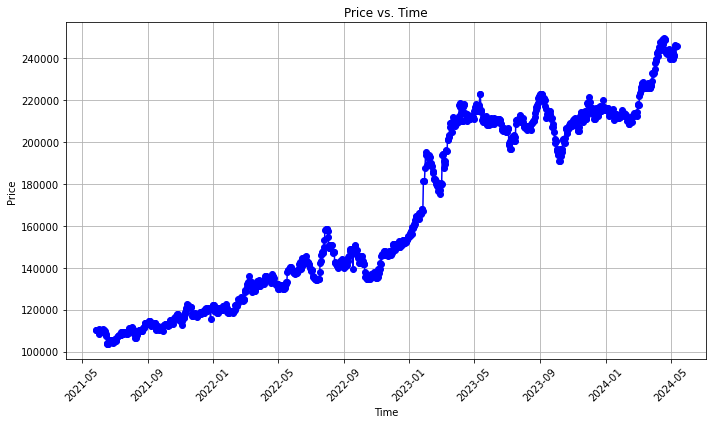

In [34]:
# Assuming 'df' is your DataFrame with columns 'Date' and 'Price'
# Make sure the 'Date' column is in datetime format

# Plotting
plt.figure(figsize=(10, 6))  # Set the figure size

# Plotting the data
plt.plot(data['date'], data['price'], color='blue', marker='o', linestyle='-')

# Adding labels and title
plt.title('Price vs. Time')
plt.xlabel('Time')
plt.ylabel('Price')

# Rotating x-axis labels for better readability (optional)
plt.xticks(rotation=45)

# Display the plot
plt.grid(True)
plt.tight_layout()
plt.show()

In [35]:
def calculate_bollinger_bands(df, window=20, num_std_dev=2):
    # Calculate rolling mean and standard deviation
    rolling_mean = df['price'].rolling(window=window).mean()
    rolling_std = df['price'].rolling(window=window).std()

    # Calculate upper and lower bands
    upper_band = rolling_mean + (rolling_std * num_std_dev)
    lower_band = rolling_mean - (rolling_std * num_std_dev)

    return upper_band, lower_band

def calculate_sma(df, window=20):
    # Calculate Simple Moving Average
    sma = df['price'].rolling(window=window).mean()
    return sma

def calculate_ema(df, window=20):
    # Calculate Exponential Moving Average
    ema = df['price'].ewm(span=window, adjust=False).mean()
    return ema

In [36]:
# Assuming 'df' is your DataFrame with columns 'Date' and 'Price'
# Make sure the 'Date' column is in datetime format

# Calculate Bollinger Bands
data['date'] = pd.to_datetime(data['date'])
upper_band, lower_band = calculate_bollinger_bands(data)
sma = calculate_sma(data)
ema = calculate_ema(data)

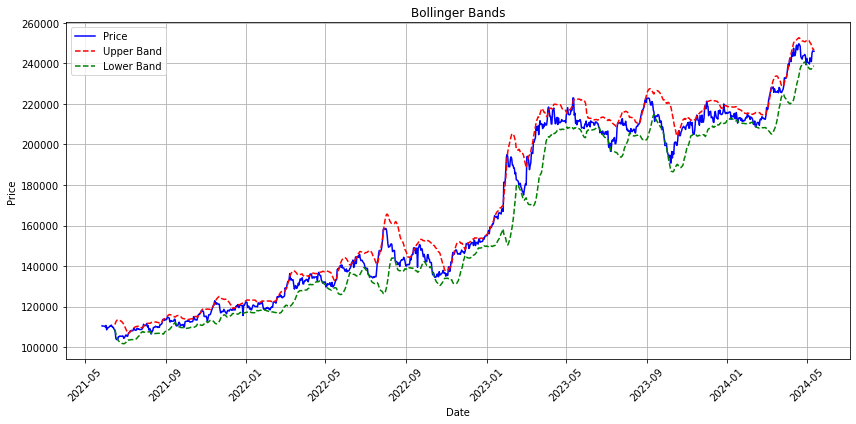

In [37]:
# Plotting BB
plt.figure(figsize=(12, 6))

# Plotting price
plt.plot(data['date'], data['price'], label='Price', color='blue')

# Plotting Bollinger Bands
plt.plot(data['date'], upper_band, label='Upper Band', color='red', linestyle='--')
plt.plot(data['date'], lower_band, label='Lower Band', color='green', linestyle='--')

# Adding labels and title
plt.title('Bollinger Bands')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()

# Display the plot
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

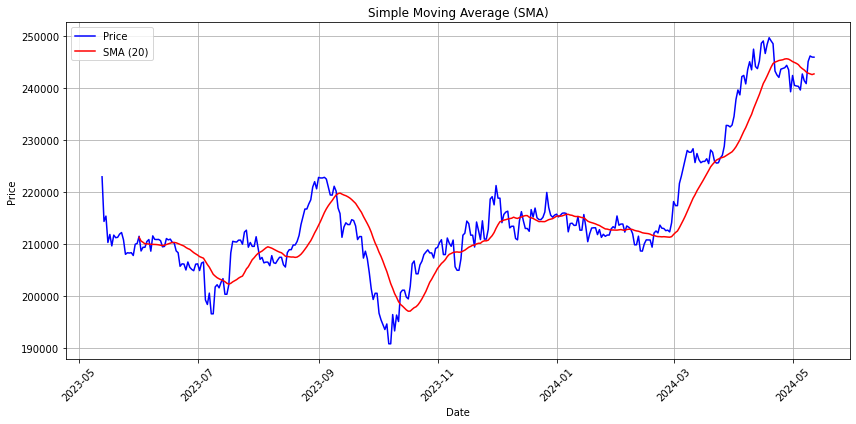

In [64]:
# Plotting SMA
plt.figure(figsize=(12, 6))

# Plotting price
plt.plot(data['date'], data['price'], label='Price', color='blue')

# Plotting SMA
plt.plot(data['date'], sma, label='SMA (20)', color='red')

# Adding labels and title
plt.title('Simple Moving Average (SMA)')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()

# Display the plot
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

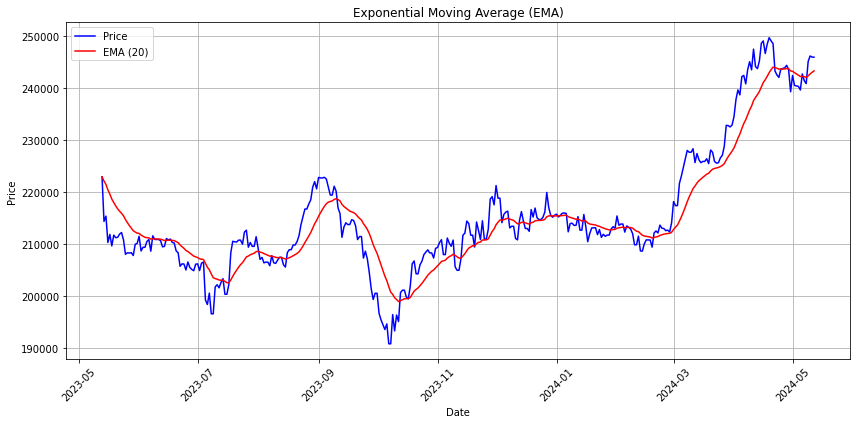

In [67]:
# Plotting EMA
plt.figure(figsize=(12, 6))

# Plotting price
plt.plot(data['date'], data['price'], label='Price', color='blue')

# Plotting EMA
plt.plot(data['date'], ema, label='EMA (20)', color='red')

# Adding labels and title
plt.title('Exponential Moving Average (EMA)')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()

# Display the plot
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()